In [1]:
# hafta 10: sifirdan GPT-2 (124M), 1. kisim

#### bu hafta GPT-2'nin en kucuk surumunu, 124 milyon parametreli olanini sifirdan yaziyorum.
# plan su:
#   task 1: openai'nin yayinladigi agirliklari hugging face'ten yukleyip icine bakiyorum. hangi agirlik var, boyutu ne,
#           toplam kac parametre, pozisyon embedding'i neye benziyor.
#   task 2: ayni mimariyi hafta 8'deki GPT'mden yola cikarak kendim yaziyorum ve openai'nin agirliklarini kendi sinifima tasiyorum.
#           iki model ayni girdiye ayni logits'i veriyorsa mimariyi birebir dogru kurmusum demektir.
#   task 3: kendi sinifimla metin uretiyorum, once ingilizce sonra turkce. turkcede neden kotu, token sayilarina bakiyorum.
#   task 4: ayni modeli bu sefer rastgele baslatiyorum, ilk loss'a bakiyorum, sonra tek bir batch'i ezberletiyorum.
#   task 5: ek olarak (b) sikkini sectim: ayni cumlenin turkcesi ve ingilizcesi icin GPT-2'nin loss'unu olcuyorum.

In [2]:
%pip install -q transformers tiktoken

Note: you may need to restart the kernel to use updated packages.


In [3]:
import math, os, time, urllib.request
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken
from transformers import GPT2LMHeadModel

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'      # mac
else:
    device = 'cpu'
print('device:', device)

/Users/aliemreaydin/.claude/jobs/75b62360/tmp/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1028 12:46:46.184000 26232 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps


## task 1
Hugging Face'ten GPT-2'yi (124M) yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını hesapla. Pozisyon embedding'ini (`wpe`) görselleştir: ne görüyorsun? (0:03:39 - 0:13:47)

In [4]:
model_hf = GPT2LMHeadModel.from_pretrained('gpt2')   # 'gpt2' = en kucuk surum, 124M
sd_hf = model_hf.state_dict()

for k, v in sd_hf.items():
    print(f'{k:42s} {str(tuple(v.shape)):14s} {v.numel():>12,d}')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 15951.61it/s]

transformer.wte.weight                     (50257, 768)     38,597,376
transformer.wpe.weight                     (1024, 768)         786,432
transformer.h.0.ln_1.weight                (768,)                  768
transformer.h.0.ln_1.bias                  (768,)                  768
transformer.h.0.attn.c_attn.weight         (768, 2304)       1,769,472
transformer.h.0.attn.c_attn.bias           (2304,)               2,304
transformer.h.0.attn.c_proj.weight         (768, 768)          589,824
transformer.h.0.attn.c_proj.bias           (768,)                  768
transformer.h.0.ln_2.weight                (768,)                  768
transformer.h.0.ln_2.bias                  (768,)                  768
transformer.h.0.mlp.c_fc.weight            (768, 3072)       2,359,296
transformer.h.0.mlp.c_fc.bias              (3072,)               3,072
transformer.h.0.mlp.c_proj.weight          (3072, 768)       2,359,296
transformer.h.0.mlp.c_proj.bias            (768,)                  768
transf

In [5]:
# state_dict'teki her seyi toplarsam lm_head ile wte iki kere sayiliyor (ayni tensor, asagida anlatiyorum)
toplam_sd = sum(v.numel() for v in sd_hf.values())
toplam = sum(p.numel() for p in model_hf.parameters())          # parameters() ortak tensoru bir kez sayar
print(f'state_dict toplami        : {toplam_sd:>12,d}')
print(f'gercek parametre sayisi   : {toplam:>12,d}')
print('lm_head ile wte ayni tensor mu:', sd_hf['lm_head.weight'].data_ptr() == sd_hf['transformer.wte.weight'].data_ptr())
print()

wte = sd_hf['transformer.wte.weight'].numel()
wpe = sd_hf['transformer.wpe.weight'].numel()
blok = sum(v.numel() for k, v in sd_hf.items() if k.startswith('transformer.h.0.'))
lnf = sum(v.numel() for k, v in sd_hf.items() if k.startswith('transformer.ln_f'))
print(f'wte (token embedding)     : {wte:>12,d}  (%{100*wte/toplam:.1f})')
print(f'wpe (pozisyon embedding)  : {wpe:>12,d}  (%{100*wpe/toplam:.1f})')
print(f'tek blok                  : {blok:>12,d}')
print(f'12 blok                   : {12*blok:>12,d}  (%{100*12*blok/toplam:.1f})')
print(f'ln_f                      : {lnf:>12,d}')
print(f'toplam                    : {wte+wpe+12*blok+lnf:>12,d}')

state_dict toplami        :  163,037,184
gercek parametre sayisi   :  124,439,808
lm_head ile wte ayni tensor mu: True

wte (token embedding)     :   38,597,376  (%31.0)
wpe (pozisyon embedding)  :      786,432  (%0.6)
tek blok                  :    7,087,872
12 blok                   :   85,054,464  (%68.3)
ln_f                      :        1,536
toplam                    :  124,439,808


In [6]:
#### ciktiyi okuyorum.
# en basta iki embedding tablosu var:
#   wte (50257, 768): token embedding. 50257 token'in her biri icin 768 sayilik bir vektor. hafta 8'deki self.tok bu.
#   wpe (1024, 768): pozisyon embedding. 1024 pozisyonun her biri icin 768 sayilik vektor. hafta 8'deki self.pos bu.
#   yani model en fazla 1024 token'a ayni anda bakabiliyor (block_size = 1024, hafta 8'de 256'ydi).
# sonra transformer.h.0'dan h.11'e kadar 12 blok var, hepsi ayni sekilde:
#   ln_1 -> attn.c_attn -> attn.c_proj -> ln_2 -> mlp.c_fc -> mlp.c_proj
#   c_attn (768, 2304): 2304 = 3 x 768. q, k ve v'yi tek katmanda birden uretiyor (task 2'de aciyorum).
#   mlp.c_fc (768, 3072): feedforward once 4 katina genisliyor (768 x 4 = 3072), c_proj geri 768'e indiriyor. hafta 8'deki 4 * n_embd ayni sey.
# en sonda ln_f (son layernorm) ve lm_head (768'den 50257 token'a skor).
#
# toplam parametre: 124.439.808, adindaki 124M bu.
# state_dict'i dumduz toplarsam 163 milyon cikiyor, cunku lm_head ile wte ayni tensor ve iki kere sayiliyor.
# buna weight tying deniyor: giristeki "token -> vektor" tablosu ile cikistaki "vektor -> token skoru" tablosu ayni matris.
# mantigi: anlamca birbirine yakin iki token girista yakin vektorlere sahipse, cikista da benzer skor almali. ayni matris bunu zorluyor.
# kazanc 38,6 milyon parametre, modelin yaklasik ucte biri.
#
# parametreler nerede: sadece token tablosu modelin %31'i. 12 blok %68. pozisyon tablosu %0,6, cok kucuk.

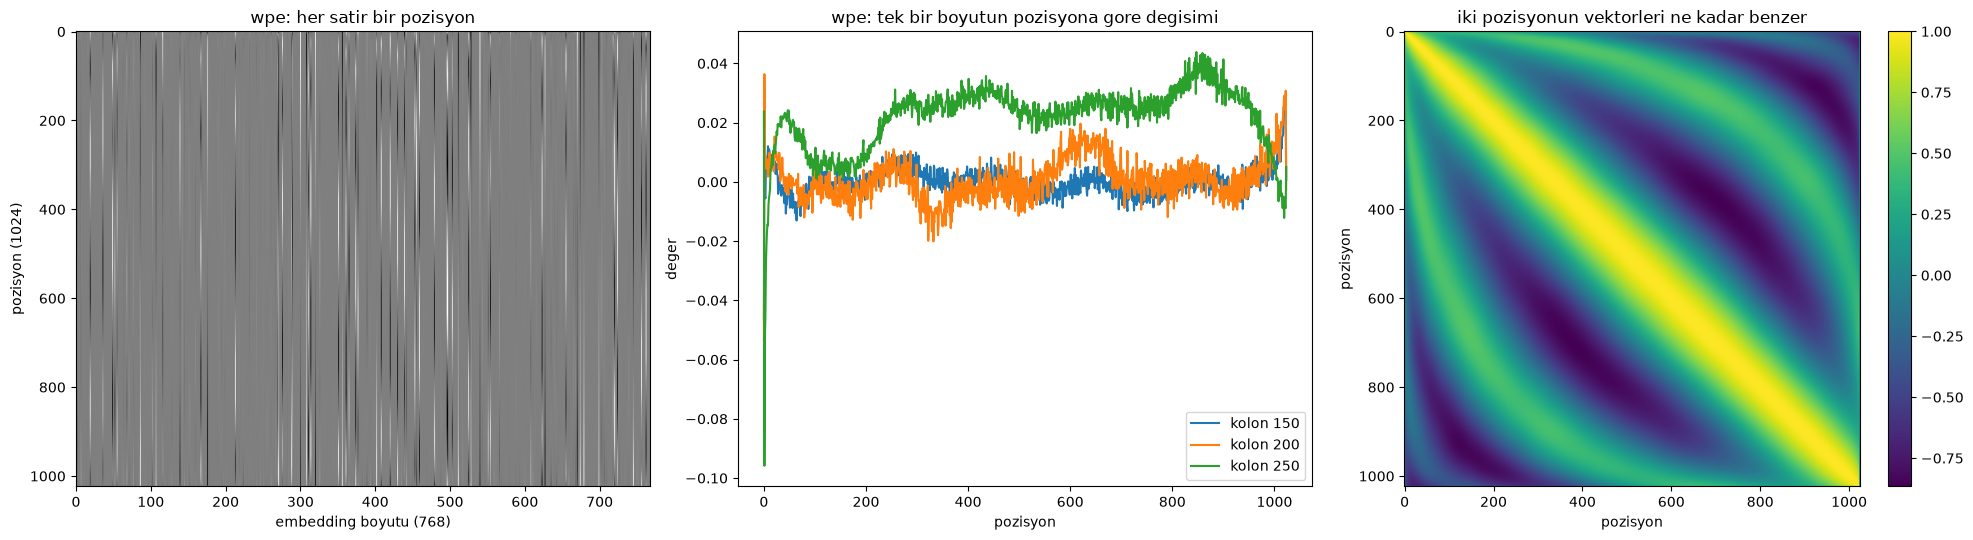

pozisyon 0 vektorunun uzunlugu: 9.88   ortanca pozisyon: 3.37
  1 adim uzaktaki pozisyonla ortalama benzerlik: 0.997
 20 adim uzaktaki pozisyonla ortalama benzerlik: 0.960
100 adim uzaktaki pozisyonla ortalama benzerlik: 0.471
500 adim uzaktaki pozisyonla ortalama benzerlik: 0.246


In [7]:
wpe_w = sd_hf['transformer.wpe.weight']       # (1024, 768)

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
v = wpe_w.abs().quantile(0.99).item()           # birkac uc deger renk olcegini ezmesin diye %99'dan kirpiyorum
ax[0].imshow(wpe_w, cmap='gray', aspect='auto', vmin=-v, vmax=v)
ax[0].set_xlabel('embedding boyutu (768)')
ax[0].set_ylabel('pozisyon (1024)')
ax[0].set_title('wpe: her satir bir pozisyon')

for j in [150, 200, 250]:
    ax[1].plot(wpe_w[:, j], label=f'kolon {j}')
ax[1].set_xlabel('pozisyon')
ax[1].set_ylabel('deger')
ax[1].set_title('wpe: tek bir boyutun pozisyona gore degisimi')
ax[1].legend()

benzerlik = F.normalize(wpe_w, dim=1) @ F.normalize(wpe_w, dim=1).T     # (1024, 1024) kosinus benzerligi
im = ax[2].imshow(benzerlik, cmap='viridis')
ax[2].set_xlabel('pozisyon')
ax[2].set_ylabel('pozisyon')
ax[2].set_title('iki pozisyonun vektorleri ne kadar benzer')
plt.colorbar(im, ax=ax[2])
plt.tight_layout()
plt.show()

uzunluk = wpe_w.norm(dim=1)
print(f'pozisyon 0 vektorunun uzunlugu: {uzunluk[0]:.2f}   ortanca pozisyon: {uzunluk.median():.2f}')
for d in [1, 20, 100, 500]:
    print(f'{d:3d} adim uzaktaki pozisyonla ortalama benzerlik: {torch.diagonal(benzerlik, d).mean():.3f}')

In [8]:
#### grafikleri okuyorum.
# soldaki resim tablonun kendisi: her satir bir pozisyon, her sutun 768 boyuttan biri.
# dikey seritler goruyorum, yani bazi boyutlar butun pozisyonlarda hep buyuk ya da hep kucuk, pozisyonla pek degismiyorlar.
# ham haliyle cizince her sey gri cikiyordu, cunku ilk pozisyonlardaki birkac uc deger renk olcegini eziyordu. o yuzden olcegi kirptim.
#
# ortadaki grafik daha anlatici: tek bir boyutu alip pozisyon boyunca cizdim. egriler pozisyonla yavas yavas inip cikiyor, dalga gibi.
# orijinal transformer makalesinde pozisyonlar sabit sinus/kosinus dalgalariyla kodlaniyordu.
# GPT-2'de bu tablo ogrenilen bir parametre, kimse ona dalga ol demedi, ama egitim sonunda kendiliginden dalgaya benzer bir sey ogrenmis.
# egriler cok tirtikli ama. karpathy videoda bunu modelin sonuna kadar egitilmemis olmasina yoruyor, tam oturmus bir modelde daha puruzsuz olurdu.
# en basta da sert bir sicrama var: pozisyon 0 ozel. olctum, pozisyon 0 vektorunun uzunlugu 9,9, ortanca pozisyonunki 3,4.
#
# sagdaki resmi ben ekledim: her pozisyon cifti icin iki vektorun ne kadar ayni yone baktigi (kosinus benzerligi). sari = ayni yone bakiyor (1), mor = ters yone bakiyor (-0,8'e kadar iniyor).
# kosegen boyunca kalin sari bir bant var: her pozisyon komsularina cok benziyor.
# 1 adim otedeki pozisyonla benzerlik 0,997, 20 adim oteyle 0,96, 100 adim oteyle 0,47.
# yani model "yakin pozisyonlar yakin vektorler" yapisini kendi kendine ogrenmis. kosegene paralel dalgali bantlar da var, yine dalga gibi tekrar eden bir yapi.
# attention bu vektorlere bakarak "bu token benden kac adim geride" bilgisini cikarabiliyor.

## task 2
GPT-2'yi hafta 8'deki GPT'nden yola çıkarak kendin yaz ve HF ağırlıklarını kendi sınıfına yükle. Aynı girdide iki modelin logits'i aynı çıksın. Hafta 8'deki modelinden farklarını madde madde yaz (aktivasyon, q/k/v'nin tek katmanda olması...). Bazı ağırlıklar neden transpoze edilerek yükleniyor? (0:13:47 - 0:31:00)

In [9]:
@dataclass
class GPTConfig:
    block_size: int = 1024    # en fazla kac token'a bakabiliyor
    vocab_size: int = 50257   # 256 byte token'i + 50.000 bpe birlestirmesi + 1 <|endoftext|>
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.n_head, self.n_embd = config.n_head, config.n_embd
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)   # tum head'lerin q, k, v'si tek katmanda
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)       # hafta 8'deki proj
        self.c_proj.SCALE_INIT = 1                                  # task 4'teki init icin isaret
        tril = torch.tril(torch.ones(config.block_size, config.block_size))
        self.register_buffer('tril', tril.view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        hs = C // self.n_head
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)              # her biri (B, T, C)
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)               # (B, nh, T, hs)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        wei = q @ k.transpose(-2, -1) * hs ** -0.5                      # (B, nh, T, T)
        wei = wei.masked_fill(self.tril[:, :, :T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        y = wei @ v                                                     # (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                # head'leri yan yana koy (hafta 8'deki torch.cat)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT = 1

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight      # weight tying: giris ve cikis ayni matris
        self.apply(self._init_weights)

    def _init_weights(self, module):
        # videodaki init (task 4'te kullaniyorum, task 2'de zaten hf agirliklarinin ustune yaziliyor)
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)      # (B, T, C)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)                                        # (B, T, vocab)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_hf(cls, sd_hf):
        model = cls(GPTConfig())
        sd = model.state_dict()
        assert set(sd) == set(sd_hf), set(sd) ^ set(sd_hf)       # isimler birebir ayni olmali
        transpoze = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        with torch.no_grad():
            for k in sd_hf:
                if any(k.endswith(w) for w in transpoze):
                    assert sd_hf[k].shape[::-1] == sd[k].shape
                    sd[k].copy_(sd_hf[k].t())
                else:
                    assert sd_hf[k].shape == sd[k].shape
                    sd[k].copy_(sd_hf[k])
        return model

In [10]:
model = GPT.from_hf(sd_hf).to(device).eval()
model_hf = model_hf.to(device).eval()
enc = tiktoken.get_encoding('gpt2')

# 1) normal bir cumle
x = torch.tensor([enc.encode("Hello, I'm a language model,")], device=device)
# 2) 1024 tokenlik rastgele dizi: tum pozisyonlar dolu
torch.manual_seed(0)
x_uzun = torch.randint(0, 50257, (2, 1024), device=device)

with torch.no_grad():
    for ad, girdi in (('cumle', x), ('rastgele 2x1024', x_uzun)):
        benim, _ = model(girdi)
        onlarin = model_hf(girdi).logits
        fark = (benim - onlarin).abs().max().item()
        print(f'{ad:16s} logits {tuple(benim.shape)}  en buyuk fark: {fark:.2e}  '
              f'allclose(atol=1e-4): {torch.allclose(benim, onlarin, atol=1e-4)}  '
              f'argmax ayni: {(benim.argmax(-1) == onlarin.argmax(-1)).all().item()}')

print()
print(f'benim modelimin parametre sayisi: {sum(p.numel() for p in model.parameters()):,d}')
print('lm_head ile wte ayni tensor mu  :', model.lm_head.weight is model.transformer.wte.weight)
print(f'weight tying olmasaydi          : {sum(p.numel() for p in model.parameters()) + model.lm_head.weight.numel():,d}')

cumle            logits (1, 8, 50257)  en buyuk fark: 8.39e-05  allclose(atol=1e-4): True  argmax ayni: True


rastgele 2x1024  logits (2, 1024, 50257)  en buyuk fark: 3.05e-04  allclose(atol=1e-4): True  argmax ayni: True

benim modelimin parametre sayisi: 124,439,808
lm_head ile wte ayni tensor mu  : True
weight tying olmasaydi          : 163,037,184


In [11]:
#### iki test yaptim.
# birincisi 8 token'lik normal bir cumle. ikincisi 1024'er token'lik iki rastgele dizi: boylece pozisyon tablosunun ve tril maskesinin tamami kullaniliyor.
# ikisinde de en buyuk fark 1e-4 mertebesinde: cumlede 8e-5, uzun dizide 3e-4.
# logits'ler -180 ile -32 arasinda sayilar, yani fark degerin milyonda birkaci. sayilar float32'nin son basamaklarinda ayrisiyor.
# sebep: hf attention'i pytorch'un hazir fonksiyonuyla (scaled_dot_product_attention) hesapliyor, ben elle q @ k.T, maske, softmax yapiyorum.
# ayni toplamalar farkli sirada yapilinca son basamaklar degisiyor.
# allclose True ve her pozisyonda en olasi token ayni. yani openai'nin agirliklari benim yazdigim sinifta birebir ayni modeli veriyor.
# parametre sayisi da 124.439.808, hf ile ayni. weight tying olmasaydi 163 milyon olurdu.

In [12]:
#### hafta 8'deki GPT'mden farklar, madde madde:
#
# 1) aktivasyon: hafta 8'de feedforward'da ReLU vardi, burada GELU var (tanh yaklasimi).
#    relu sifirin altini tamamen kesiyor, o bolgede gradient sifir. gelu sifirin altinda yumusakca sifira iniyor, kucuk de olsa gradient akiyor.
#    neden tanh yaklasimi: 2019'da tam formul yavas oldugu icin openai bu yaklasimi kullanmis. ayni sayilari almak icin ben de ayni yaklasimi kullanmak zorundayim.
#
# 2) q, k, v tek katmanda: hafta 8'de her head ayri bir Head nesnesiydi, her birinde 3 ayri Linear vardi, sonra hepsini torch.cat ile birlestiriyordum.
#    burada tek bir c_attn katmani 768'den 2304'e cikiyor: tum head'lerin q'su, k'si ve v'si tek matmul'da.
#    sonra view ile 12 head'e boluyorum, transpose ile head boyutunu one aliyorum, boylece 12 head paralel calisiyor, sanki batch'in bir parcasiymis gibi.
#    matematik ayni, sadece 36 kucuk matris carpimi yerine tek buyuk carpim, gpu icin cok daha hizli.
#
# 3) bias: hafta 8'de key/query/value bias=False'tu. GPT-2'de c_attn'de dahil butun linear'larda bias var, sadece lm_head'de yok.
#
# 4) weight tying: hafta 8'de self.tok ile cikis katmani ayri matrislerdi. burada wte ve lm_head ayni matris, 38,6 milyon parametre tasarrufu.
#
# 5) dropout yok: hafta 8'de dropout=0.2 vardi. burada hf agirliklarini birebir dogrulamak ve task 4'te tek batch ezberletmek istiyorum, ikisinde de dropout istemiyorum.
#
# 6) boyutlar: hafta 8'de harf seviyesinde vocab 65 (shakespeare) ya da 102 (nutuk) idi, burada bpe token'lari ile 50257.
#    block_size 256 -> 1024, n_embd 384 -> 768, n_head 6 -> 12, n_layer 6 -> 12.
#
# 7) isimler: katmanlara hugging face ile birebir ayni isimleri verdim (transformer.h.0.attn.c_attn gibi), cunku agirliklari isimle eslestirerek kopyaliyorum.
#    tril'i persistent=False ile kaydettim, boylece state_dict'e girmiyor, openai'nin dosyasinda boyle bir agirlik yok.
#
# ayni kalanlar: layernorm her alt blogun ONUNDE (pre-norm), residual baglantilar ve en sondaki ln_f.
# bunlari hafta 8'de zaten boyle yazmistim. orijinal transformer makalesinde layernorm toplamadan SONRA geliyordu, GPT-2 makalesi onu basa almis ve en sona bir tane eklemis.

In [13]:
#### bazi agirliklar neden transpoze ediliyor?
# openai GPT-2'yi tensorflow'da yazmis. lineer katmanlara "Conv1D" demisler ve agirligi (giris, cikis) sirasinda saklamislar:
# c_attn hf dosyasinda (768, 2304). yani 768 giris, 2304 cikis.
# pytorch'un nn.Linear'i ayni matrisi ters sirada, (cikis, giris) olarak tutuyor ve x @ W.T hesapliyor: benim c_attn'im (2304, 768).
# matris ayni, sadece satir ve sutunlari yer degistirmis halde kaydedilmis. o yuzden .t() ile cevirip kopyaliyorum.
# bu sadece Conv1D olan dort agirlikta var: attn.c_attn, attn.c_proj, mlp.c_fc, mlp.c_proj.
# embedding tablolari, layernorm agirliklari ve bias'lar transpoze edilmiyor, cunku onlar lineer katman degil.
# lm_head de edilmiyor: hf'te o zaten pytorch nn.Linear'i ve wte ile ayni tensor.
# transpozu unutsam c_attn ve mlp'deki dikdortgen matrislerde boyut tutmaz, assert hemen patlar.
# ama attn.c_proj kare (768, 768): transpozsuz da boyut tutuyor, hata vermiyor. bunu asagida bilerek deniyorum.

In [14]:
# deneme: kare olan attn.c_proj'u bilerek transpoze etmeden yukluyorum, baska hicbir sey degismiyor
yanlis = GPT.from_hf(sd_hf)
with torch.no_grad():
    for i in range(12):
        yanlis.transformer.h[i].attn.c_proj.weight.copy_(sd_hf[f'transformer.h.{i}.attn.c_proj.weight'])
yanlis = yanlis.to(device).eval()

with torch.no_grad():
    l_yanlis, _ = yanlis(x)
    l_hf = model_hf(x).logits
print('hata verdi mi: hayir, calisti')
print(f'en buyuk fark: {(l_yanlis - l_hf).abs().max().item():.2f}')
print(f'en olasi token ayni olan pozisyon: {(l_yanlis.argmax(-1) == l_hf.argmax(-1)).sum().item()} / {x.size(1)}')
print()
print('dogru model sonraki token olarak bunu bekliyor :', [enc.decode([t]) for t in l_hf[0].argmax(-1).tolist()])
print('transpozsuz model bunu bekliyor               :', [enc.decode([t]) for t in l_yanlis[0].argmax(-1).tolist()])
del yanlis

hata verdi mi: hayir, calisti
en buyuk fark: 161.68
en olasi token ayni olan pozisyon: 1 / 8

dogru model sonraki token olarak bunu bekliyor : [',', ' I', "'m", ' sorry', ' little', ' expert', 'er', ' not']
transpozsuz model bunu bekliyor               : [',', '\n', '.', '.', ' the', '.', '\n', ' the']


In [15]:
#### hata vermedi, model calisti ve sayi uretti. ama en buyuk fark artik 0,0001 degil, 162.
# 8 pozisyonun sadece 1'inde en olasi token ayni.
# dogru model "Hello"dan sonra ",", "I"dan sonra "'m", "a"dan sonra " little" gibi mantikli devamlar bekliyor.
# transpozsuz model ise hep ",", ".", "\n", " the" gibi en sik gecen token'lari tekrarliyor: dili tamamen kaybetmis.
# yani bu hata hicbir uyari vermeden modeli sessizce bozuyor. "kod calisti" yetmez, logits'i referans modelle birebir karsilastirmak lazim.
# yukaridaki iki testin (fark 1e-4, argmax birebir) asil degeri bu.

## task 3
Sampling döngüsünü top-k ile yaz. Önce İngilizce, sonra Türkçe bir başlangıçla üret. GPT-2 Türkçede neden kötü? Aynı cümle GPT-2 tokenizer'ında kaç token? Hafta 9 sonuçlarına bağla. (0:31:00 - 0:45:50)

In [16]:
def generate(model, prompt, n_seq=4, max_new_tokens=30, top_k=50, seed=42):
    tokens = enc.encode(prompt)
    x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0).repeat(n_seq, 1)   # (n_seq, T)
    torch.manual_seed(seed)
    model.eval()
    for _ in range(max_new_tokens):
        with torch.no_grad():
            logits, _ = model(x[:, -model.config.block_size:])        # pozisyon tablosu 1024 satir, fazlasini kirp
        probs = F.softmax(logits[:, -1, :], dim=-1)                   # sadece son pozisyonun tahmini lazim
        topk_probs, topk_idx = torch.topk(probs, top_k, dim=-1)       # en olasi 50 token
        ix = torch.multinomial(topk_probs, 1)                         # 50'nin icinden olasiliga gore sec
        x = torch.cat((x, torch.gather(topk_idx, -1, ix)), dim=1)
    return [enc.decode(row) for row in x.tolist()]

for s in generate(model, "Hello, I'm a language model,"):
    print('>', s.replace('\n', ' '))

> Hello, I'm a language model, not a function, but rather a way of expressing this in terms of an unbroken line. I am very happy that we have some of the best
> Hello, I'm a language model, and I have this idea that no one needs to know what to write, whether you want to write it or not. It's about understanding what is
> Hello, I'm a language model, not an engineering machine. That's the whole point.  I don't think anyone with any experience of science will ever understand it — but that
> Hello, I'm a language model, so this is like a problem that I'm supposed to solve. Now, look: is there any problem that I haven't explained to you yet?


In [17]:
for s in generate(model, "Merhaba, ben bir dil modeliyim,"):
    print('>', s.replace('\n', ' '))

> Merhaba, ben bir dil modeliyim, cada dela è adebíl que emperà de emperam.  Lemur (Gulk), de
> Merhaba, ben bir dil modeliyim, dech bizim uen bizim.  In a book entitled The Making of an American Indian, A. C. Hurd
> Merhaba, ben bir dil modeliyim, ben bhab shalaim, ben dal niyim,  dal sekim. ben kashim, ayyad
> Merhaba, ben bir dil modeliyim, baal, siyang-wlu lai shu siyana shu, the sunnah is alaa lahi-wlu


In [18]:
#### ingilizcede cumleler akici ve dilbilgisi dogru: "not an engineering machine. That's the whole point." gibi.
# anlam bazen kayiyor ama 124 milyon parametrelik bir model icin iyi.
# turkcede model hemen dagiliyor: "cada dela è adebíl que" gibi ispanyolca/italyancaya benzeyen seyler, "ben bhab shalaim" gibi uydurma kelimeler,
# bir ornekte de turkceyi birakip ingilizceye geciyor: "In a book entitled The Making of an American Indian".
# yani "ben", "bizim" gibi birkac kelimeyi taniyor ama turkce cumle kuramiyor.
# neden: GPT-2 WebText denen bir veriyle egitildi. makalenin 3.7 bolumu ingilizce olmayan sayfalari bilerek ayikladiklarini soyluyor,
# sonradan kontrol ettiklerinde tum veride sadece 10 MB fransizca kalmis. turkce de buna benzer sekilde cok az.
# ustune tokenizer da ingilizce metinde egitildigi icin turkce kelimeleri cok kucuk parcalara boluyor, asagida sayiyorum.
#
# top-k ne yapiyor: her adimda 50257 token'in hepsinden degil, en olasi 50'sinden seciyorum.
# kuyruktaki binlerce dusuk olasilikli token tek tek kucuk ama toplamda ciddi bir pay tutuyor. top-k olmasa arada bir sacma bir token secilir ve metin raydan cikar.
# 50'nin icinde ise olasiliklari yeniden normalize edip oranlarina gore seciyorum (multinomial), o yuzden her ornek farkli.

In [19]:
cl100k = tiktoken.get_encoding('cl100k_base')    # hafta 9'da kullandigim GPT-4 tokenizer'i

cumleler = {
    'EN': "Hello, I am a language model and I am trying to write sentences in Turkish.",
    'TR': "Merhaba, ben bir dil modeliyim ve Türkçe cümleler kurmaya çalışıyorum.",
}

def parcalar(e, s):
    return [e.decode_single_token_bytes(t).decode('utf-8', errors='replace') for t in e.encode(s)]

for dil, s in cumleler.items():
    kelime = len(s.split())
    g2, g4 = len(enc.encode(s)), len(cl100k.encode(s))
    print(f'{dil}: {kelime} kelime | gpt2: {g2} token ({g2/kelime:.2f}/kelime) | cl100k: {g4} token ({g4/kelime:.2f}/kelime)')
    print('    gpt2  :', '|'.join(parcalar(enc, s)))
    print('    cl100k:', '|'.join(parcalar(cl100k, s)))
    print()

EN: 15 kelime | gpt2: 17 token (1.13/kelime) | cl100k: 17 token (1.13/kelime)
    gpt2  : Hello|,| I| am| a| language| model| and| I| am| trying| to| write| sentences| in| Turkish|.
    cl100k: Hello|,| I| am| a| language| model| and| I| am| trying| to| write| sentences| in| Turkish|.

TR: 10 kelime | gpt2: 34 token (3.40/kelime) | cl100k: 27 token (2.70/kelime)
    gpt2  : Mer|hab|a|,| ben| bir| dil| model|iy|im| ve| T|ür|k|ç|e| c|ü|m|le|ler| k|ur|may|a| �|�|al|ı|ş|ı|y|orum|.
    cl100k: Mer|hab|a|,| ben| bir| dil| model|iy|im| ve| Tür|k|ç|e| c|üm|le|ler| kur|m|aya| çalış|ı|y|orum|.



In [20]:
#### ayni cumle, ingilizcede 15 kelime 17 token: kelime basina 1,13. neredeyse her kelime tek token.
# turkcede 10 kelime 34 token: kelime basina 3,40. ingilizcenin 3 katindan fazla.
# parcalara bakinca: "Türkçe" -> T|ür|k|ç|e, "cümleler" -> c|ü|m|le|ler. turkce harflerin cogu tek basina bir token.
# en carpici yer "çalışıyorum": ç harfi UTF-8'de 2 byte ve GPT-2 onu iki ayri token'a bolmus.
# iki parca da tek basina gecerli bir karakter degil, o yuzden ekranda � olarak gorunuyor. hafta 9'daki byte seviyesi bpe'nin sonucu bu.
#
# hafta 9'da ayni olcumu cl100k (GPT-4'un tokenizer'i) ile Nutuk'tan bir paragrafta yapmistim: turkcede kelime basina 2,57, ingilizcede 1,24 token cikmisti.
# bu cumlede cl100k 2,70 veriyor, GPT-2 3,40. GPT-2'nin tokenizer'i turkcede daha da kotu:
# vocab'i yarisi kadar (50.257'ye karsi 100.277) ve egitim metninde turkce cok az oldugu icin "ç", "ş" gibi byte ikilileri birlestirme listesine bile girememis.
# hafta 9'daki mantigin aynisi: bpe sik gecen ikilileri birlestiriyor, turkce sik gecmediyse turkce parcalar birlesmiyor.
# eklemeli yapi da isi zorlastiriyor: "kurmaya" -> k|ur|may|a. kok ve ekler ayri parcalar olsa model "kur" + "maya" diye ogrenebilirdi, ama kelime rastgele yerlerden bolunmus.
# modele etkisi: ayni cumle icin 2-3 kat fazla adim, block_size'a 2-3 kat az turkce metin sigiyor ve model anlamsiz byte parcalarindan kelime kurmak zorunda kaliyor.

## task 4
Modeli rastgele başlat. İlk loss ≈ ln(50257) ≈ 10.8 çıkıyor mu, neden buna yakın olmalı? Tek bir batch'i ezberlet (birkaç yüz adım, loss → 0). Bu test neden işe yarıyor? (0:45:50 - 1:02:00)

In [21]:
if not os.path.exists('input.txt'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt', 'input.txt')
text = open('input.txt', encoding='utf-8').read()
tokens = enc.encode(text[:2000])

B, T = 4, 32
buf = torch.tensor(tokens[:B*T + 1])
x = buf[:-1].view(B, T).to(device)     # girdi
y = buf[1:].view(B, T).to(device)      # hedef: girdinin bir adim kaydirilmisi
buf2 = torch.tensor(tokens[B*T:2*B*T + 1])
x2, y2 = buf2[:-1].view(B, T).to(device), buf2[1:].view(B, T).to(device)   # hic gormedigi ikinci batch (kontrol icin)

torch.manual_seed(1337)
model_r = GPT(GPTConfig()).to(device)     # rastgele baslatilmis, hf agirligi yok

with torch.no_grad():
    logits, loss = model_r(x, y)
p = F.softmax(logits, dim=-1)
print(f'ilk loss           : {loss.item():.4f}')
print(f'ln(50257)          : {math.log(50257):.4f}')
print(f'1/50257            : {1/50257:.2e}')
print(f'dogru token olasiligi (ortalama): {p.gather(-1, y.unsqueeze(-1)).mean().item():.2e}')
print(f'en olasi token olasiligi (ort.) : {p.max(-1).values.mean().item():.2e}')
print(f'logits std         : {logits.std().item():.4f}')

ilk loss           : 10.9600
ln(50257)          : 10.8249
1/50257            : 1.99e-05
dogru token olasiligi (ortalama): 2.01e-05
en olasi token olasiligi (ort.) : 1.74e-04
logits std         : 0.5546


In [22]:
#### ilk loss 10,96, ln(50257) = 10,82. cok yakin.
# neden yakin olmali: model daha hicbir sey ogrenmedi. o zaman hicbir token'i digerine tercih etmemeli, hepsine esit olasilik vermeli: 1/50257.
# cross entropy, dogru token'a verilen olasiligin eksi logaritmasi: -ln(1/50257) = ln(50257) = 10,82.
# ciktida bunu goruyorum: dogru token'a verilen olasilik ortalama 2,01e-5, yani tam 1/50257 kadar.
# en olasi token bile ortalama 1,7e-4. hicbir token one cikmiyor, softmax neredeyse dumduz.
#
# bunu saglayan init (videodaki): agirliklari ortalamasi 0, std'si 0,02 olan normal dagilimla baslattim. logits kucuk kaliyor (std 0,55), softmax duz cikiyor.
# residual'a ekleme yapan c_proj'lari ayrica 1/sqrt(2 x 12) ile kucultuyorum:
# her blok residual'a iki kere ekleme yapiyor (attention + mlp), 12 blokta 24 ekleme ust uste biniyor. kucultmesem toplamin varyansi bloktan bloka buyurdu.
#
# ilk loss 10,8'den cok buyuk ciksaydi, ornegin 30, model rastgele ama EMIN tahminler yapiyor demekti. hafta 4'teki initial loss patlamasi, "confidently wrong".
# o zaman ilk yuzlerce adim bir sey ogrenmeye degil, o yersiz guveni torpulemeye gidiyor. 10,96 tam aradigim sey.

adim   0  loss 10.9600


adim  25  loss 2.7336


adim  50  loss 0.3249


adim  75  loss 0.0127


adim 100  loss 0.0040


...

adim 200  loss 0.0013


adim 225  loss 0.0011


adim 250  loss 0.0010


adim 275  loss 0.0009


adim 299  loss 0.0008
sure: 21.5 sn


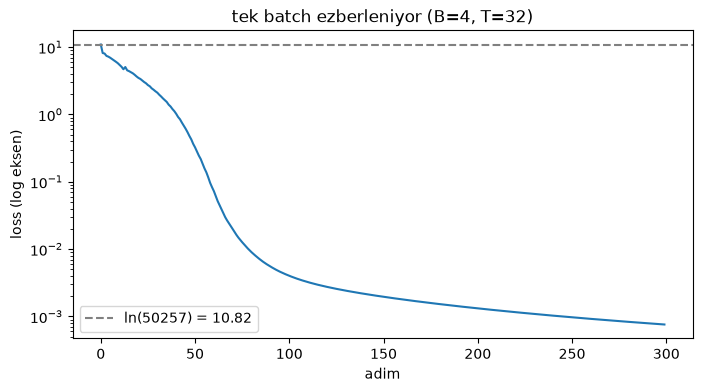

In [23]:
optimizer = torch.optim.AdamW(model_r.parameters(), lr=3e-4)
losses = []
t0 = time.time()
model_r.train()
for step in range(300):
    optimizer.zero_grad()
    logits, loss = model_r(x, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if step % 25 == 0 or step == 299:
        print(f'adim {step:3d}  loss {loss.item():.4f}')
print(f'sure: {time.time() - t0:.1f} sn')

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.yscale('log')
plt.axhline(math.log(50257), color='gray', ls='--', label='ln(50257) = 10.82')
plt.xlabel('adim')
plt.ylabel('loss (log eksen)')
plt.title('tek batch ezberleniyor (B=4, T=32)')
plt.legend()
plt.show()

In [24]:
#### 128 token'lik tek bir batch'i (4 satir x 32 token) 300 adim boyunca tekrar tekrar gosteriyorum.
# loss 10,96'dan 25 adimda 2,73'e, 50 adimda 0,32'ye, 100 adimda 0,004'e iniyor. 300. adimda 0,0008.
# grafik log eksende: 50 ile 75. adim arasinda dik bir dusus var, sonrasinda her adimda biraz daha yavas ama durmayan bir inis.
#
# bu test neden ise yariyor: 124 milyon parametreli bir modelin 128 token'i ezberleyememesi icin hicbir sebep yok, kapasite fazlasiyla yeterli.
# o yuzden loss sifira gitmiyorsa sorun modelde degil kodda: hedefleri bir adim kaydirmayi unutmusumdur, zero_grad yoktur,
# gradient bir yerde kopuyordur, optimizer yanlis parametreleri guncelliyordur, learning rate sacmadir.
# tek batch'te bu hatalarin hepsi kendini hemen belli ediyor ve deneme birkac saniye suruyor. buyuk egitime baslamadan once en ucuz saglik kontrolu.
#
# yakalayamadigi bir hata da var: tril maskesini unutsam loss yine sifira giderdi, hatta daha hizli, cunku model cevabi gelecekten kopyalardi.
# bir de testin hic gostermedigi sey: model genellemeyi ogrendi mi. bunu bir alttaki hucrede goruyorum.

In [25]:
# ezberledigi metni geri uretebiliyor mu? batch'in ilk satirinin sadece ilk token'ini verip gerisini greedy uretiyorum
model_r.eval()
gercek = x[0].tolist()
uretilen = x[0:1, :1]
with torch.no_grad():
    for _ in range(T - 1):
        logits, _ = model_r(uretilen)
        uretilen = torch.cat((uretilen, logits[:, -1, :].argmax(-1, keepdim=True)), dim=1)
uretilen = uretilen[0].tolist()

print('batchteki metin :', repr(enc.decode(gercek)))
print('modelin urettigi:', repr(enc.decode(uretilen)))
print(f'{T} token\'in {sum(a == b for a, b in zip(gercek, uretilen))} tanesi ayni')
print()
with torch.no_grad():
    print(f'ezberledigi batch loss : {model_r(x, y)[1].item():.4f}')
    print(f'hic gormedigi batch    : {model_r(x2, y2)[1].item():.4f}')

batchteki metin : 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are'
modelin urettigi: 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are'
32 token'in 32 tanesi ayni

ezberledigi batch loss : 0.0008
hic gormedigi batch    : 11.6162


In [26]:
#### kendi modelimin urettigi metin: batch'in ilk satirindan sadece ilk token'i ("First") verdim, gerisini model her adimda en olasi token'i secerek uretti.
# 32 token'in 32'si birebir ayni: "First Citizen: Before we proceed any further, hear me speak. All: Speak, speak. First Citizen: You are"
# yani ezber tam.
# ama hic gormedigi bir sonraki 128 token'da loss 11,6. rastgele baslangictaki 10,96'dan bile kotu.
# model shakespeare ogrenmedi, sadece bu 128 token'i ezberledi. ustune bu token'lara asiri guvenir hale geldi, o yuzden yeni metinde esit tahmin yapan rastgele modelden bile kotu.
# bu overfit'in en uc hali: ezberledigi veride 0,0008, gormedigi veride 11,6. hafta 4'teki LoL nick modelinde train 2,16 / dev 3,09 farki vardi, bu onun asiri versiyonu.
# gercekten ogrenmesi icin tum metinde egitmek lazim: batch'leri metin boyunca kaydiran bir data loader (videonun 1:02'den sonrasi, ek gorev a).

## task 5 (ek, b)
Yüklü GPT-2 ile bir Türkçe cümlenin loss'unu, İngilizce karşılığının loss'uyla karşılaştır. Fark neden bu kadar büyük?

In [27]:
ciftler = [
    ("The weather was beautiful this morning, so I decided to walk to the university.",
     "Bu sabah hava çok güzeldi, bu yüzden üniversiteye yürümeye karar verdim."),
    ("On the way, I stopped at a small cafe and drank a cup of tea.",
     "Yolda küçük bir kafede durdum ve bir bardak çay içtim."),
    ("The history of this city goes back thousands of years.",
     "Bu şehrin tarihi binlerce yıl öncesine dayanıyor."),
]

def olc(s):
    ids = torch.tensor([enc.encode(s)], device=device)
    with torch.no_grad():
        _, loss = model(ids[:, :-1], ids[:, 1:])     # her token'i oncekilerden tahmin et (ilk token haric)
    n = ids.size(1) - 1
    return loss.item(), loss.item() * n, n

print(f'{"":4s}{"token":>6s}{"token basi loss":>17s}{"cumle toplami":>15s}{"karakter basi":>15s}')
toplam = {'EN': [0, 0, 0], 'TR': [0, 0, 0]}
for en, tr in ciftler:
    for dil, s in (('EN', en), ('TR', tr)):
        ort, top, n = olc(s)
        toplam[dil][0] += top; toplam[dil][1] += n; toplam[dil][2] += len(s)
        print(f'{dil:4s}{n:6d}{ort:17.3f}{top:15.1f}{top/len(s):15.3f}   {s}')
    print()
for dil, (top, n, c) in toplam.items():
    print(f'{dil} genel: token basi {top/n:.3f}  |  cumle toplami {top:.1f}  |  karakter basi {top/c:.3f}  |  token basi perplexity {math.exp(top/n):.0f}')

     token  token basi loss  cumle toplami  karakter basi
EN      15            3.201           48.0          0.608   The weather was beautiful this morning, so I decided to walk to the university.
TR      35            5.715          200.0          2.778   Bu sabah hava çok güzeldi, bu yüzden üniversiteye yürümeye karar verdim.

EN      16            2.694           43.1          0.707   On the way, I stopped at a small cafe and drank a cup of tea.
TR      26            5.570          144.8          2.682   Yolda küçük bir kafede durdum ve bir bardak çay içtim.

EN      10            2.673           26.7          0.495   The history of this city goes back thousands of years.
TR      24            6.277          150.6          3.074   Bu şehrin tarihi binlerce yıl öncesine dayanıyor.

EN genel: token basi 2.875  |  cumle toplami 117.9  |  karakter basi 0.607  |  token basi perplexity 18
TR genel: token basi 5.829  |  cumle toplami 495.5  |  karakter basi 2.831  |  token basi perplexity

In [28]:
#### ayni anlamdaki uc cumle ciftinin loss'u. uc farkli olcu yazdirdim, cunku hangisine baktigim sonucu degistiriyor.
# token basi loss: EN 2,88, TR 5,83. perplexity olarak: ingilizcede model her adimda sanki ~18 secenek arasinda kararsiz, turkcede ~340.
# ama token basi loss iki dili adil kiyaslamiyor, cunku turkce cumle iki kattan fazla token'a bolunuyor (85'e karsi 41).
# adil olcu, ayni anlami tasiyan metnin toplam loss'u: model bu cumleyi okurken toplamda ne kadar "sasiriyor". EN 117,9, TR 495,5, turkce 4,2 kat.
# karakter basi da benzer: EN 0,61, TR 2,83, 4,7 kat.
#
# neden bu kadar buyuk, uc sebep ust uste biniyor:
#   1) veri: GPT-2'nin egitim verisi ingilizce. model turkce ekleri, kelime sirasini, hangi kelimenin hangisinden sonra geldigini neredeyse hic gormedi.
#   2) daha cok tahmin: turkce cumle iki kat fazla token. her token bir tahmin ve her tahmin toplam loss'a bir terim ekliyor. hem tahmin sayisi fazla hem her biri daha zor.
#   3) anlamsiz parcalar: "c|ü|m|le|ler" gibi parcalardan sonra ne gelecegini tahmin etmek, "sentences" gibi butun bir kelimeden sonrakini tahmin etmekten cok daha zor.
#      model kelime degil harf grubu tahmin ediyor ve o harf gruplarini da az gormus.
#
# hafta 8'de "iki dilin val loss'u dogrudan kiyaslanir mi" diye sorulmustu, burada da cevap ayni:
# token basi loss kiyaslanmaz cunku token'lar iki dilde ayni buyuklukte degil. ayni metni karakter basina ya da toplam loss olarak olcmek lazim.

In [29]:
#### ozet
# - GPT-2 124M = 124.439.808 parametre. %31'i token tablosu, %68'i 12 blok. weight tying 38,6 milyon parametre kazandiriyor.
# - pozisyon tablosu ogreniliyor ama kendiliginden dalgaya benzer bir yapi ogrenmis: komsu pozisyonlar birbirine cok benziyor.
# - kendi yazdigim GPT sinifi, openai agirliklariyla hf'in modeliyle ayni logits'i veriyor (fark 1e-4 mertebesinde, en olasi token her yerde ayni).
# - hafta 8'den farklar: gelu, tek c_attn, bias'lar, weight tying, dropout yok, GPT-2 boyutlari. 4 agirlik Conv1D'den geldigi icin transpoze ediliyor.
# - ingilizcede akici metin uretiyor, turkcede dagiliyor: veri ingilizce, tokenizer turkceyi 3 kat fazla parcaya boluyor.
# - rastgele init'te ilk loss 10,96, ln(50257) = 10,82'ye yakin: model her token'a esit olasilik veriyor.
# - tek batch 300 adimda 0,0008'e indi ve model ezberledigi metni birebir geri uretti. kod dogru calisiyor, ama gormedigi metinde 11,6: bu ogrenme degil ezber.
# - ayni anlamdaki turkce cumlelerin toplam loss'u ingilizce karsiliklarinin 4,2 kati.